## Medical LLM

In [1]:
import gzip, json, time, random
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from tqdm.auto import tqdm
from lxml import etree

SEED = 42
random.seed(SEED); np.random.seed(SEED)

RAW_DIR = Path.home() / "Downloads" / "PubmedData"
OUT_DIR = Path("data"); OUT_DIR.mkdir(exist_ok=True)
JSONL_PATH = OUT_DIR / "pubmed_abstracts.jsonl"
files = sorted(RAW_DIR.glob("pubmed*.xml.gz"))

/Users/sowmyasivaram/PycharmProjects/JupyterProject/.venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Task 1

In [2]:
n_seen, n_kept = 0, 0
with open(JSONL_PATH, "w", encoding="utf-8") as out:
    for path in tqdm(files, desc="Parsing files"):
        with gzip.open(path, "rb") as fh:
            for _, art in etree.iterparse(fh, tag="PubmedArticle"):
                n_seen += 1

                pmid = art.findtext(".//MedlineCitation/PMID")
                title_el = art.find(".//ArticleTitle")
                title = "".join(title_el.itertext()).strip() if title_el is not None else ""

                parts = []
                for ab in art.findall(".//Abstract/AbstractText"):
                    t = "".join(ab.itertext()).strip()
                    if t:
                        label = ab.get("Label")
                        parts.append(f"{label}: {t}" if label else t)
                abstract = " ".join(parts).strip()

                year = art.findtext(".//Journal/JournalIssue/PubDate/Year")
                if year is None:
                    medline_date = art.findtext(".//Journal/JournalIssue/PubDate/MedlineDate") or ""
                    year = medline_date[:4] if medline_date[:4].isdigit() else None
                language = art.findtext(".//Language")

                if abstract:
                    rec = {"pmid": pmid, "title": title, "abstract": abstract, "year": year, "language": language}
                    out.write(json.dumps(rec, ensure_ascii=False) + "\n")
                    n_kept += 1

                art.clear()
                while art.getprevious() is not None:
                    del art.getparent()[0]

print(f"Articles seen: {n_seen:,} | with abstract kept: {n_kept:,}")
from datasets import load_dataset

ds = load_dataset("json", data_files=str(JSONL_PATH), split="train")
ds = ds.filter(lambda x: len(x["abstract"].split()) >= 20)
ds = ds.map(lambda x: {"n_words": len(x["abstract"].split()), "n_chars": len(x["abstract"])})
splits = ds.train_test_split(test_size=0.05, seed=SEED)
train_ds, val_ds = splits["train"], splits["test"]

Parsing files: 100%|██████████| 20/20 [00:54<00:00,  2.71s/it]


Articles seen: 600,000 | with abstract kept: 261,125


/Users/sowmyasivaram/PycharmProjects/JupyterProject/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
Generating train split: 261125 examples [00:00, 481726.15 examples/s]
Map: 100%|██████████| 260733/260733 [00:16<00:00, 15825.73 examples/s]


No. of abstracts: 260,733
Total words: 33,946,123
        n_words   n_chars
count  260733.0  260733.0
mean      130.2     877.3
std        65.4     433.4
min        20.0     108.0
25%        82.0     556.0
50%       120.0     813.0
75%       167.0    1124.0
max       671.0    4203.0

Languages: {'eng': 214264, 'ger': 18103, 'fre': 10645, 'rus': 10372, 'ita': 2296}
Years: min 1975 max 1980


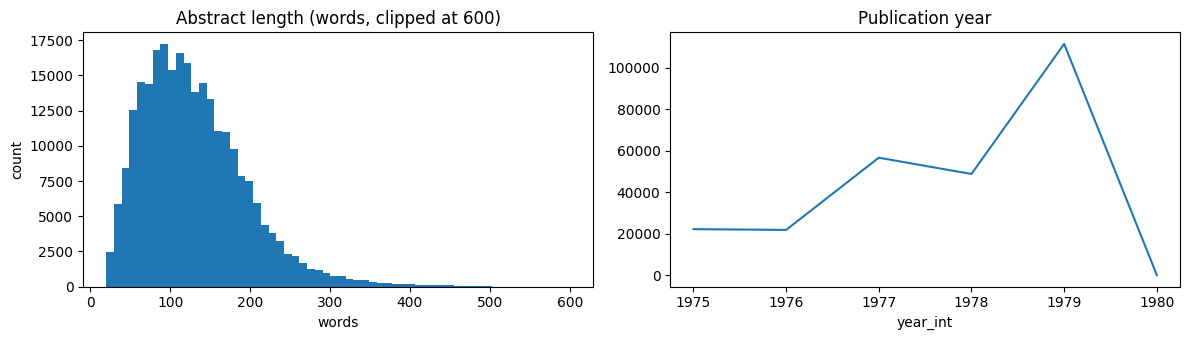

In [3]:
df = ds.to_pandas()
df["year_int"] = pd.to_numeric(df["year"], errors="coerce")

print(f"No. of abstracts: {len(df):,}")
print(f"Total words: {df.n_words.sum():,}")
print(df[["n_words", "n_chars"]].describe().round(1))
print("\nLanguages:", df.language.value_counts().head(5).to_dict())
print("Years: min", df.year_int.min(), "max", df.year_int.max())

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].hist(df.n_words.clip(upper=600), bins=60)
ax[0].set_title("Abstract length (words, clipped at 600)"); ax[0].set_xlabel("words"); ax[0].set_ylabel("count")
df.year_int.dropna().astype(int).value_counts().sort_index().plot(ax=ax[1], title="Publication year")
plt.tight_layout(); plt.show()

## Task 2

In [4]:
from tokenizers import Tokenizer, models, normalizers, pre_tokenizers, decoders, trainers, processors

VOCAB_SIZE = 16_000
EOT, UNK = "<|endoftext|>", "[UNK]"

train_texts = train_ds["abstract"]
val_texts = val_ds["abstract"]
text_batches = [train_texts[i:i + 1000] for i in range(0, len(train_texts), 1000)]

tokenizers, train_time = {}, {}

for name in ["BPE", "WordPiece", "Unigram", "Byte-level BPE"]:
    if name == "BPE":
        tok = Tokenizer(models.BPE(unk_token=UNK))
        tok.normalizer = normalizers.Sequence([normalizers.NFD(), normalizers.StripAccents()])
        tok.pre_tokenizer = pre_tokenizers.Whitespace()
        tok.decoder = decoders.BPEDecoder()
        trainer = trainers.BpeTrainer(vocab_size=VOCAB_SIZE, special_tokens=[UNK, EOT])
    elif name == "WordPiece":
        tok = Tokenizer(models.WordPiece(unk_token=UNK))
        tok.normalizer = normalizers.Sequence([normalizers.NFD(), normalizers.StripAccents()])
        tok.pre_tokenizer = pre_tokenizers.BertPreTokenizer()
        tok.decoder = decoders.WordPiece(prefix="##")
        trainer = trainers.WordPieceTrainer(vocab_size=VOCAB_SIZE, special_tokens=[UNK, EOT])
    elif name == "Unigram":
        tok = Tokenizer(models.Unigram())
        tok.normalizer = normalizers.NFKC()
        tok.pre_tokenizer = pre_tokenizers.Metaspace()
        tok.decoder = decoders.Metaspace()
        trainer = trainers.UnigramTrainer(vocab_size=VOCAB_SIZE, special_tokens=[UNK, EOT], unk_token=UNK)
    else:  # Byte-level BPE: the 256-byte alphabet means no unknown token is ever needed
        tok = Tokenizer(models.BPE())
        tok.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
        tok.decoder = decoders.ByteLevel()
        trainer = trainers.BpeTrainer(vocab_size=VOCAB_SIZE, special_tokens=[EOT],
                                      initial_alphabet=pre_tokenizers.ByteLevel.alphabet())

    t0 = time.time()
    tok.train_from_iterator(text_batches, trainer=trainer)
    train_time[name] = time.time() - t0
    tokenizers[name] = tok
    print(f"{name:15s} trained in {train_time[name]:5.1f}s | vocab = {tok.get_vocab_size()}")




BPE             trained in   5.5s | vocab = 16000



WordPiece       trained in   7.4s | vocab = 16000


Unigram         trained in  61.2s | vocab = 16000



Byte-level BPE  trained in   7.7s | vocab = 16000


In [5]:
eval_texts = val_texts[:2000]
n_chars = sum(len(t) for t in eval_texts)

rows = []
for name, tok in tokenizers.items():
    t0 = time.time()
    enc = tok.encode_batch(eval_texts)
    dt = time.time() - t0

    all_ids = [i for e in enc for i in e.ids]
    unk_id = tok.token_to_id(UNK)
    unk_rate = 0.0 if unk_id is None else sum(i == unk_id for i in all_ids) / len(all_ids)

    rows.append({
        "Method": name,
        "Vocab size": tok.get_vocab_size(),
        "Avg tokens / abstract": round(len(all_ids) / len(eval_texts), 1),
        "Chars / token": round(n_chars / len(all_ids), 2),
        "UNK rate": f"{unk_rate:.4%}",
        "Train time (s)": round(train_time[name], 1),
        "Encode speed (abstracts/s)": int(len(eval_texts) / dt),
    })

comparison = pd.DataFrame(rows).set_index("Method")
comparison

,Vocab size,Avg tokens / abstract,Chars / token,UNK rate,Train time (s),Encode speed (abstracts/s)
Method,,,,,,
BPE,16000,169.2,5.13,0.0000%,5.5,10329
WordPiece,16000,173.7,4.99,0.0000%,7.4,22212
Unigram,16000,166.9,5.20,0.0000%,61.2,14258
Byte-level BPE,16000,175.2,4.95,0.0000%,7.7,9556


In [6]:
medical_terms = ["electrocardiogram", "hypercholesterolemia", "acetylsalicylic", "thrombocytopenia",
                 "immunosuppression", "chemotherapy", "pneumonia", "5-fluorouracil"]

split_table = pd.DataFrame({name: {t: " | ".join(tok.encode(t).tokens) for t in medical_terms}
                            for name, tok in tokenizers.items()})
pd.set_option("display.max_colwidth", None)
split_table

,BPE,WordPiece,Unigram,Byte-level BPE
electrocardiogram,electrocardiogram,electrocardiogram,▁electro | cardiogram,electro | cardi | ogram
hypercholesterolemia,hypercholesterole | mia,hypercholesterol | ##emia,▁hyper | cholesterolemia,hyper | choles | terole | mia
acetylsalicylic,acetylsalicylic,acetylsal | ##icylic,▁acetylsalicylic,acetyl | salicylic
thrombocytopenia,thrombocytopenia,thrombocytopenia,▁ | thrombocytopenia,throm | b | ocyt | openia
immunosuppression,immunosuppression,immunosuppression,▁immuno | suppression,immun | os | upp | ression
chemotherapy,chemotherapy,chemotherapy,▁chemotherapy,chem | otherapy
pneumonia,pneumonia,pneumonia,▁pneumonia,p | neum | onia
5-fluorouracil,5 | - | fluorouracil,5 | - | fluorouracil,▁5-fluorouracil,5 | - | fluorouracil


In [7]:
sample = eval_texts[0][:200]
print("ORIGINAL:", sample, "\n")
for name, tok in tokenizers.items():
    print(f"[{name}]", tok.decode(tok.encode(sample).ids)[:200], "\n")

ORIGINAL: T and B lymphocyte populations were monitored in the peripheral blood of two long-term plateletpheresis donors. The studies showed minimal fluctuation of both populations compared to the normal contro 

[BPE] TandBlymphocytepopulationsweremonitoredintheperipheralbloodoftwolong-termplateletpheresisdonors.Thestudiesshowedminimalfluctuationofbothpopulationscomparedtothenormalcontro 

[WordPiece] T and B lymphocyte populations were monitored in the peripheral blood of two long - term plateletpheresis donors. The studies showed minimal fluctuation of both populations compared to the normal cont 

[Unigram] T and B lymphocyte populations were monitored in the peripheral blood of two long-term plateletpheresis donors. The studies showed minimal fluctuation of both populations compared to the normal contro 

[Byte-level BPE] T and B lymphocyte populations were monitored in the peripheral blood of two long-term plateletpheresis donors. The studies showed minimal fluctuation of both po

The round-trip test  on a PubMed abstract gave:

| Method | Round-trip result on the sample |
|---|---|
| BPE | Spaces are lost: `TandBlymphocytepopulationsweremonitored...` |
| WordPiece | Spaces are inserted around punctuation: `long - term`, `donors .` |
| Unigram | Matches the original on this sample |
| Byte-level BPE | Matches the original exactly |


### Final choice: Byte-level BPE

We chose **byte-level BPE** because:

1. It is the only method here whose output matches the original text exactly in the test above.
2. Medical text is full of drug names, gene symbols, units, Greek letters and numbers. Byte-level BPE can represent all of them.
3. It does not strip accents or rewrite characters, so `µg`, `β-blocker`, `≥` and similar medical symbols are preserved.
4. A word like `plateletpheresis` is split into smaller known pieces instead of being lost, while frequent words stay as single tokens.

The cost, slightly longer sequences for rare words, is small compared with the benefit of lossless text in a medical setting.

In [8]:
tokenizer = tokenizers["Byte-level BPE"]
tokenizer.post_processor = processors.ByteLevel(trim_offsets=False)
tokenizer.save(str(OUT_DIR / "tokenizer.json"))

EOT_ID = tokenizer.token_to_id(EOT)
VOCAB = tokenizer.get_vocab_size()
print("EOT id:", EOT_ID, "| vocab size:", VOCAB)

EOT id: 0 | vocab size: 16000


## Task 3

In [9]:
import torch

text = "Aspirin reduces the risk of myocardial infarction."
ids = tokenizer.encode(text).ids
x, y = ids[:-1], ids[1:]

print(f"{'pos':<5}{'input':<18}{'target':<18}")
for i in range(len(x)):
    print(f"{i:<5}{tokenizer.decode([x[i]])!r:<18}{tokenizer.decode([y[i]])!r:<18}")

causal_mask = torch.tril(torch.ones(len(x), len(x))).int()
print("\nCausal attention mask (row = query position, column = key position, 1 = allowed):")
print(causal_mask)

pos  input             target            
0    'Asp'             'irin'            
1    'irin'            ' reduces'        
2    ' reduces'        ' the'            
3    ' the'            ' risk'           
4    ' risk'           ' of'             
5    ' of'             ' myocardial'     
6    ' myocardial'     ' infarction'     
7    ' infarction'     '.'               

Causal attention mask (row = query position, column = key position, 1 = allowed):
tensor([[1, 0, 0, 0, 0, 0, 0, 0],
        [1, 1, 0, 0, 0, 0, 0, 0],
        [1, 1, 1, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 0],
        [1, 1, 1, 1, 1, 1, 1, 1]], dtype=torch.int32)


## Task 4

In [11]:
BLOCK_SIZE = 256
BATCH_SIZE = 32

train_stream, val_stream = [], []
for texts, stream, desc in [(train_texts, train_stream, "train"), (val_texts, val_stream, "val")]:
    for i in tqdm(range(0, len(texts), 2000), desc=f"Tokenizing {desc}"):
        for enc in tokenizer.encode_batch(texts[i:i + 2000]):
            stream.extend(enc.ids)
            stream.append(EOT_ID)

train_stream = torch.tensor(train_stream, dtype=torch.long)
val_stream = torch.tensor(val_stream, dtype=torch.long)
print(f"Train tokens: {len(train_stream):,} | Val tokens: {len(val_stream):,}")

Tokenizing val: 100%|██████████| 7/7 [00:01<00:00,  5.04it/s]

Train tokens: 43,875,528 | Val tokens: 2,313,458


In [12]:
from torch.utils.data import Dataset, DataLoader
import lightning as L

class PackedLMDataset(Dataset):
    def __init__(self, stream, block_size):
        self.block_size = block_size
        self.n_blocks = (len(stream) - 1) // block_size
        self.stream = stream

    def __len__(self):
        return self.n_blocks

    def __getitem__(self, idx):
        start = idx * self.block_size
        chunk = self.stream[start : start + self.block_size + 1]
        return {
            "input_ids": chunk[:-1],
            "labels": chunk[1:].clone(),
            "attention_mask": torch.ones(self.block_size, dtype=torch.long),
        }

class PubMedDataModule(L.LightningDataModule):
    def __init__(self, train_set, val_set, batch_size=32, num_workers=0):
        super().__init__()
        self.train_set, self.val_set = train_set, val_set
        self.batch_size, self.num_workers = batch_size, num_workers

    def train_dataloader(self):
        return DataLoader(self.train_set, batch_size=self.batch_size, shuffle=True,
                          num_workers=self.num_workers, drop_last=True)

    def val_dataloader(self):
        return DataLoader(self.val_set, batch_size=self.batch_size, shuffle=False,
                          num_workers=self.num_workers)

train_set = PackedLMDataset(train_stream, BLOCK_SIZE)
val_set = PackedLMDataset(val_stream, BLOCK_SIZE)
dm = PubMedDataModule(train_set, val_set, batch_size=BATCH_SIZE)
print(f"Train blocks: {len(train_set):,} | Val blocks: {len(val_set):,}")

Train blocks: 171,388 | Val blocks: 9,036


In [13]:
batch = next(iter(dm.train_dataloader()))
for k, v in batch.items():
    print(f"{k:15s} shape={tuple(v.shape)} dtype={v.dtype}")

print("\n--- Example 0: input_ids decoded (first 600 chars) ---")
print(tokenizer.decode(batch["input_ids"][0].tolist(), skip_special_tokens=False)[:600])

print("\n--- Shift check: labels[:-1] == input_ids[1:] ---")
print("OK" if torch.equal(batch["labels"][0, :-1], batch["input_ids"][0, 1:]) else "MISMATCH")

print("\n--- First 12 (input -> target) pairs ---")
for a, b in list(zip(batch["input_ids"][0].tolist(), batch["labels"][0].tolist()))[:12]:
    print(f"{tokenizer.decode([a])!r:>18} -> {tokenizer.decode([b])!r}")

print(f"\n<|endoftext|> tokens in this batch: {(batch['input_ids'] == EOT_ID).sum().item()}")

input_ids       shape=(32, 256) dtype=torch.int64
labels          shape=(32, 256) dtype=torch.int64
attention_mask  shape=(32, 256) dtype=torch.int64

--- Example 0: input_ids decoded (first 600 chars) ---
 also demonstrated that Triosorb decreased progressively. This may be interpreted to be due to the increase of TBG binding capacity which is increased progressively and binds more of free thyroxine during pregnancy. Such a change in TBG binding capacity is well known to be caused by the effect of estrogen which is progressively increased during pregnancy. In a word, it is possible to say that there is a placento-thyroidal system in pregnancy; HCT elevates thyroid function and TBG increased by estrogen carries thyroid hormone to target organ.<|endoftext|>A technique is described for the daily i

--- Shift check: labels[:-1] == input_ids[1:] ---
OK

--- First 12 (input -> target) pairs ---
           ' also' -> ' demonstrated'
   ' demonstrated' -> ' that'
           ' that' -> ' T'
  

## Task 5

In [14]:
import math
import torch.nn as nn
import torch.nn.functional as F

device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print("Device:", device)

class CausalSelfAttention(nn.Module):
    def __init__(self, d_model, n_head, block_size, dropout):
        super().__init__()
        assert d_model % n_head == 0, "d_model must be divisible by n_head"
        self.n_head, self.d_head = n_head, d_model // n_head
        self.qkv = nn.Linear(d_model, 3 * d_model)
        self.proj = nn.Linear(d_model, d_model)
        self.attn_drop = nn.Dropout(dropout)
        self.resid_drop = nn.Dropout(dropout)
        mask = torch.tril(torch.ones(block_size, block_size)).view(1, 1, block_size, block_size)
        self.register_buffer("mask", mask, persistent=False)

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=2)
        q = q.view(B, T, self.n_head, self.d_head).transpose(1, 2)
        k = k.view(B, T, self.n_head, self.d_head).transpose(1, 2)
        v = v.view(B, T, self.n_head, self.d_head).transpose(1, 2)

        scores = (q @ k.transpose(-2, -1)) / math.sqrt(self.d_head)
        scores = scores.masked_fill(self.mask[:, :, :T, :T] == 0, float("-inf"))
        weights = self.attn_drop(F.softmax(scores, dim=-1))
        out = weights @ v
        out = out.transpose(1, 2).contiguous().view(B, T, C)
        return self.resid_drop(self.proj(out))

class TransformerBlock(nn.Module):
    def __init__(self, d_model, n_head, block_size, dropout):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = CausalSelfAttention(d_model, n_head, block_size, dropout)
        self.ln2 = nn.LayerNorm(d_model)
        self.mlp = nn.Sequential(nn.Linear(d_model, 4 * d_model), nn.GELU(),
                                 nn.Linear(4 * d_model, d_model), nn.Dropout(dropout))

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        x = x + self.mlp(self.ln2(x))
        return x

class GPT(nn.Module):
    def __init__(self, vocab_size, block_size, n_layer=4, n_head=4, d_model=256, dropout=0.1):
        super().__init__()
        self.block_size = block_size
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(block_size, d_model)
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([TransformerBlock(d_model, n_head, block_size, dropout) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight

        self.apply(self._init_weights)
        for name, p in self.named_parameters():
            if name.endswith("proj.weight") or name.endswith("mlp.2.weight"):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * n_layer))

    def _init_weights(self, m):
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)

    def forward(self, input_ids):
        B, T = input_ids.shape
        assert T <= self.block_size, "sequence longer than block_size"
        pos = torch.arange(T, device=input_ids.device)
        x = self.drop(self.tok_emb(input_ids) + self.pos_emb(pos))
        for block in self.blocks:
            x = block(x)
        return self.head(self.ln_f(x))

Device: mps


In [15]:
N_LAYER, N_HEAD, D_MODEL, DROPOUT = 4, 4, 256, 0.1
model = GPT(VOCAB, BLOCK_SIZE, N_LAYER, N_HEAD, D_MODEL, DROPOUT).to(device)
n_params = sum(p.numel() for p in model.parameters())
n_emb = model.tok_emb.weight.numel() + model.pos_emb.weight.numel()
print(f"Total parameters       : {n_params:,} ({n_params / 1e6:.2f} M)")
print(f"  embeddings           : {n_emb:,}")
print(f"  transformer blocks   : {sum(p.numel() for p in model.blocks.parameters()):,}")

batch = next(iter(dm.train_dataloader()))
model.eval()
with torch.no_grad():
    logits = model(batch["input_ids"].to(device))
print(f"\ninput_ids shape : {tuple(batch['input_ids'].shape)}   (batch x block_size)")
print(f"logits shape    : {tuple(logits.shape)}   (batch x sequence x vocabulary)")

loss = F.cross_entropy(logits.reshape(-1, VOCAB), batch["labels"].to(device).reshape(-1))
print(f"\nInitial loss: {loss.item():.3f} | expected about ln(vocab) = {math.log(VOCAB):.3f}")
x = batch["input_ids"][:1].to(device)
x2 = x.clone(); x2[0, 100] = (x2[0, 100] + 1) % VOCAB
with torch.no_grad():
    l1, l2 = model(x), model(x2)
print("Logits before position 100 unchanged:", torch.allclose(l1[:, :100], l2[:, :100], atol=1e-5))
print("Logits from position 100 onward changed:", not torch.allclose(l1[:, 100:], l2[:, 100:], atol=1e-5))

Total parameters       : 7,321,088 (7.32 M)
  embeddings           : 4,161,536
  transformer blocks   : 3,159,040

input_ids shape : (32, 256)   (batch x block_size)
logits shape    : (32, 256, 16000)   (batch x sequence x vocabulary)

Initial loss: 9.734 | expected about ln(vocab) = 9.680
Logits before position 100 unchanged: True
Logits from position 100 onward changed: True


## Task 6

In [16]:
import shutil
from lightning.pytorch.callbacks import ModelCheckpoint
from lightning.pytorch.loggers import CSVLogger

class MedGPTLightning(L.LightningModule):
    def __init__(self, vocab_size, block_size, n_layer=4, n_head=4, d_model=256, dropout=0.1, lr=6e-4, weight_decay=0.1, warmup_steps=200, max_steps=3000):
        super().__init__()
        self.save_hyperparameters()
        self.model = GPT(vocab_size, block_size, n_layer, n_head, d_model, dropout)

    def forward(self, input_ids):
        return self.model(input_ids)

    def _loss(self, batch):
        logits = self.model(batch["input_ids"])                                  # (B, T, V)
        return F.cross_entropy(logits.reshape(-1, logits.size(-1)), batch["labels"].reshape(-1))

    def training_step(self, batch, batch_idx):
        loss = self._loss(batch)
        self.log("train_loss", loss, prog_bar=True)
        return loss

    def validation_step(self, batch, batch_idx):
        loss = self._loss(batch)
        self.log("val_loss", loss, prog_bar=True)

    def test_step(self, batch, batch_idx):
        loss = self._loss(batch)
        self.log("test_loss", loss)
        self.log("test_ppl", torch.exp(loss))

    def predict_step(self, batch, batch_idx):
        return self.model(batch["input_ids"]).argmax(dim=-1)

    def configure_optimizers(self):
        hp = self.hparams
        decay = [p for p in self.model.parameters() if p.requires_grad and p.dim() >= 2]
        no_decay = [p for p in self.model.parameters() if p.requires_grad and p.dim() < 2]
        opt = torch.optim.AdamW([{"params": decay, "weight_decay": hp.weight_decay},
                                 {"params": no_decay, "weight_decay": 0.0}], lr=hp.lr, betas=(0.9, 0.95))

        def lr_lambda(step):
            if step < hp.warmup_steps:
                return (step + 1) / hp.warmup_steps
            progress = (step - hp.warmup_steps) / max(1, hp.max_steps - hp.warmup_steps)
            return 0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * min(1.0, progress)))

        sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)
        return {"optimizer": opt, "lr_scheduler": {"scheduler": sched, "interval": "step"}}

In [17]:
MAX_STEPS = 3000
CKPT_EVERY = 500
VAL_EVERY = 250
L.seed_everything(SEED)
shutil.rmtree("checkpoints", ignore_errors=True)

lit_model = MedGPTLightning(VOCAB, BLOCK_SIZE, N_LAYER, N_HEAD, D_MODEL, DROPOUT, lr=6e-4, weight_decay=0.1, warmup_steps=200, max_steps=MAX_STEPS)

best_ckpt = ModelCheckpoint(dirpath="checkpoints/best", monitor="val_loss", mode="min", save_top_k=1, filename="best")
step_ckpt = ModelCheckpoint(dirpath="checkpoints/steps", every_n_train_steps=CKPT_EVERY,save_top_k=-1, save_last=True,
                            filename="step-{step}", auto_insert_metric_name=False)
csv_logger = CSVLogger("logs", name="medgpt")

trainer = L.Trainer(max_steps=MAX_STEPS, accelerator="auto", devices=1,
                    logger=csv_logger, callbacks=[best_ckpt, step_ckpt],
                    log_every_n_steps=25, val_check_interval=VAL_EVERY, limit_val_batches=50,
                    gradient_clip_val=1.0)

trainer.fit(lit_model, datamodule=dm)
print("Best checkpoint:", best_ckpt.best_model_path)

Seed set to 42
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores


┏━━━┳━━━━━━━┳━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name  ┃ Type ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━╇━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model │ GPT  │  7.3 M │ train │     0 │
└───┴───────┴──────┴────────┴───────┴───────┘

Trainable params: 7.3 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 7.3 M                                                                                                
Total estimated model params size (MB): 29                                                                         
Modules in train mode: 59                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

/Users/sowmyasivaram/PycharmProjects/JupyterProject/.venv/lib/python3.9/site-packages/rich/live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/Users/sowmyasivaram/PycharmProjects/JupyterProject/.venv/lib/python3.9/site-packages/lightning/pytorch/trainer/con
nectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider 
increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.

/Users/sowmyasivaram/PycharmProjects/JupyterProject/.venv/lib/python3.9/site-packages/lightning/pytorch/trainer/con
nectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. 
Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve 
performance.

`Trainer.fit` stopped: `max_steps=3000` reached.


Best checkpoint: /Users/sowmyasivaram/PycharmProjects/JupyterProject/checkpoints/best/best.ckpt


In [19]:
sel_blocks = 50 * BATCH_SIZE
split_at = max(sel_blocks, len(val_set) // 2)
test_set = PackedLMDataset(val_stream[split_at * BLOCK_SIZE:], BLOCK_SIZE)
print(f"test blocks: {len(test_set):,}")

class PubMedDataModuleWithTest(PubMedDataModule):
    def __init__(self, train_set, val_set, test_set, batch_size=32, num_workers=0):
        super().__init__(train_set, val_set, batch_size=batch_size, num_workers=num_workers)
        self.test_set = test_set

    def test_dataloader(self):
        return DataLoader(self.test_set, batch_size=self.batch_size, shuffle=False,
                          num_workers=self.num_workers)

dm_test = PubMedDataModuleWithTest(train_set, val_set, test_set, batch_size=BATCH_SIZE)
test_results = trainer.test(lit_model, datamodule=dm_test, ckpt_path=best_ckpt.best_model_path)
print(test_results)
print(f"Test perplexity = exp(test_loss) = {math.exp(test_results[0]['test_loss']):.2f}")

Restoring states from the checkpoint path at /Users/sowmyasivaram/PycharmProjects/JupyterProject/checkpoints/best/best.ckpt
Loaded model weights from the checkpoint at /Users/sowmyasivaram/PycharmProjects/JupyterProject/checkpoints/best/best.ckpt


test blocks: 4,518


/Users/sowmyasivaram/PycharmProjects/JupyterProject/.venv/lib/python3.9/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'test_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│         test_loss         │      4.4851975440979      │
│         test_ppl          │     88.93567657470703     │
└───────────────────────────┴───────────────────────────┘

[{'test_loss': 4.4851975440979, 'test_ppl': 88.93567657470703}]
Test perplexity = exp(test_loss) = 88.69


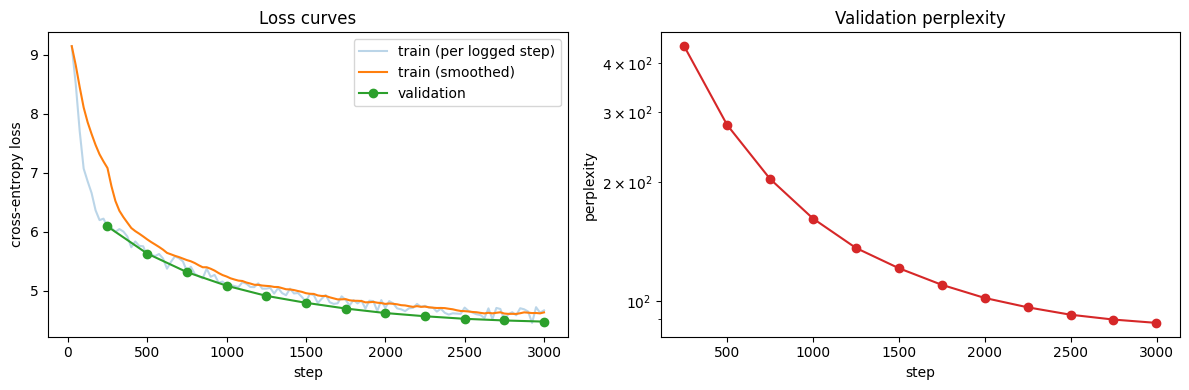

In [20]:
metrics = pd.read_csv(Path(csv_logger.log_dir) / "metrics.csv")
train_curve = metrics[["step", "train_loss"]].dropna()
val_curve = metrics[["step", "val_loss"]].dropna()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(train_curve.step, train_curve.train_loss, alpha=0.3, label="train (per logged step)")
ax[0].plot(train_curve.step, train_curve.train_loss.rolling(10, min_periods=1).mean(), label="train (smoothed)")
ax[0].plot(val_curve.step, val_curve.val_loss, "o-", label="validation")
ax[0].set_xlabel("step"); ax[0].set_ylabel("cross-entropy loss"); ax[0].set_title("Loss curves"); ax[0].legend()

ax[1].plot(val_curve.step, np.exp(val_curve.val_loss), "o-", color="tab:red")
ax[1].set_xlabel("step"); ax[1].set_ylabel("perplexity"); ax[1].set_title("Validation perplexity"); ax[1].set_yscale("log")
plt.tight_layout(); plt.show()

In [21]:
one_block = train_set[0]
pred_loader = DataLoader([one_block], batch_size=1)
pred = trainer.predict(lit_model, dataloaders=pred_loader, ckpt_path=best_ckpt.best_model_path)[0]
print("Context  :", tokenizer.decode(one_block["input_ids"][:30].tolist()))
print("Predicted:", tokenizer.decode(pred[0, :30].tolist()))
print("True     :", tokenizer.decode(one_block["labels"][:30].tolist()))

Restoring states from the checkpoint path at /Users/sowmyasivaram/PycharmProjects/JupyterProject/checkpoints/best/best.ckpt
Loaded model weights from the checkpoint at /Users/sowmyasivaram/PycharmProjects/JupyterProject/checkpoints/best/best.ckpt


/Users/sowmyasivaram/PycharmProjects/JupyterProject/.venv/lib/python3.9/site-packages/rich/live.py:260: 
UserWarning: install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/Users/sowmyasivaram/PycharmProjects/JupyterProject/.venv/lib/python3.9/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.


Context  : Ratings from 84 students of selected attitudes before a brief introduction to a method of meditation and responses afterward correlated moderately, suggesting those favoring
Predicted: R). the patients with the patients to and period period of the single of theically. the to the and with with and that ofors the
True     : atings from 84 students of selected attitudes before a brief introduction to a method of meditation and responses afterward correlated moderately, suggesting those favoring personal


In [22]:
@torch.no_grad()
def generate(model, prompt, max_new_tokens=80, do_sample=False, temperature=1.0, top_k=None, top_p=None, seed=0):
    model.eval()
    g = torch.Generator().manual_seed(seed)
    idx = torch.tensor([tokenizer.encode(prompt).ids], device=device)

    for _ in range(max_new_tokens):
        logits = model(idx[:, -BLOCK_SIZE:])[:, -1, :]
        if not do_sample:
            next_id = logits.argmax(dim=-1, keepdim=True)
        else:
            logits = logits / temperature
            if top_k is not None:
                kth_value = torch.topk(logits, top_k).values[:, -1, None]
                logits = logits.masked_fill(logits < kth_value, float("-inf"))
            if top_p is not None:
                sorted_logits, sorted_idx = torch.sort(logits, descending=True)
                cum_probs = torch.softmax(sorted_logits, dim=-1).cumsum(dim=-1)
                remove = cum_probs > top_p
                remove[:, 1:] = remove[:, :-1].clone()
                remove[:, 0] = False
                sorted_logits = sorted_logits.masked_fill(remove, float("-inf"))
                logits = torch.full_like(logits, float("-inf")).scatter(1, sorted_idx, sorted_logits)
            probs = torch.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs.cpu(), 1, generator=g).to(device)

        if next_id.item() == EOT_ID:
            break
        idx = torch.cat([idx, next_id], dim=1)

    return tokenizer.decode(idx[0].tolist())

In [23]:
# Load an early and the final checkpoint
step_files = sorted(Path("checkpoints/steps").glob("step-*.ckpt"), key=lambda p: int(p.stem.split("-")[1]))
ckpt_paths = {"early": step_files[0], "final": Path("checkpoints/steps/last.ckpt")}

models = {}
for name, path in ckpt_paths.items():
    models[name] = MedGPTLightning.load_from_checkpoint(path, map_location="cpu").model.to(device).eval()
    print(f"{name:6s} <- {path}")

early  <- checkpoints/steps/step-500.ckpt
final  <- checkpoints/steps/last.ckpt


In [24]:
prompts = [
    "The patient presented with",
    "Treatment of type 2 diabetes includes",
    "The most common side effects of chemotherapy are",
    "Hypertension is a major risk factor for",
    "In this randomized controlled trial, patients were assigned to",
]
strategies = {
    "greedy":          dict(do_sample=False),
    "temperature=0.7": dict(do_sample=True, temperature=0.7),
    "top-k=40":        dict(do_sample=True, temperature=1.0, top_k=40),
    "top-p=0.9":       dict(do_sample=True, temperature=1.0, top_p=0.9),
}

rows = []
for ckpt_name, m in models.items():
    for prompt in prompts:
        for strat_name, kwargs in strategies.items():
            text = generate(m, prompt, max_new_tokens=80, seed=SEED, **kwargs)
            rows.append({"checkpoint": ckpt_name, "prompt": prompt, "strategy": strat_name, "text": text})
samples_df = pd.DataFrame(rows)

for prompt in prompts:
    print("=" * 100); print("PROMPT:", prompt)
    for ckpt_name in models:
        for strat_name in strategies:
            t = samples_df[(samples_df.checkpoint == ckpt_name) & (samples_df.prompt == prompt) & (samples_df.strategy == strat_name)].text.iloc[0]
            print(f"\n[{ckpt_name} | {strat_name}]\n{t}")

PROMPT: The patient presented with

[early | greedy]
The patient presented with a patient with a patient with a patient with a patient with a patient with a patient with a patient with a patient with a patient with a patient with a patient with a patient with a patient with a patient with a patient with a patient with a patient with a patient with a patient with a patient with a patient with a patient with a patient with a patient with a patient with a patient with a patient

[early | temperature=0.7]
The patient presented with a patient's patient with a patients are reported that the first-t's patient's syndrome.

[early | top-k=40]
The patient presented with a patient's patient. The patients are reported that these-induced or a patient's syndrome may be attributed to be reported.

[early | top-p=0.9]
The patient presented with malignant them'sologic tests. In this work that like ventricularyanide is treated patient's syndrome may indicate that a high pathogenesis of methadone or duod

,loss,perplexity,top-1 acc,top-5 acc,top-10 acc
validation,4.4834,88.5388,0.2595,0.4600,0.5391
test,4.4852,88.6945,0.2595,0.4593,0.5390


Reference: a uniform guess gives loss 9.68 / perplexity 16000


n  loss_per_word  tokens_per_word  \
ckpt  group                                                       
early function words      76545          2.484              1.0   
      general scientific   6464          4.505              1.0   
      medical terms        1525          7.341              1.0   
final function words      76545          2.008              1.0   
      general scientific   6464          3.380              1.0   
      medical terms        1525          5.466              1.0   

                          loss_per_token  
ckpt  group                               
early function words               2.484  
      general scientific           4.505  
      medical terms                7.341  
final function words               2.008  
      general scientific           3.380  
      medical terms                5.466

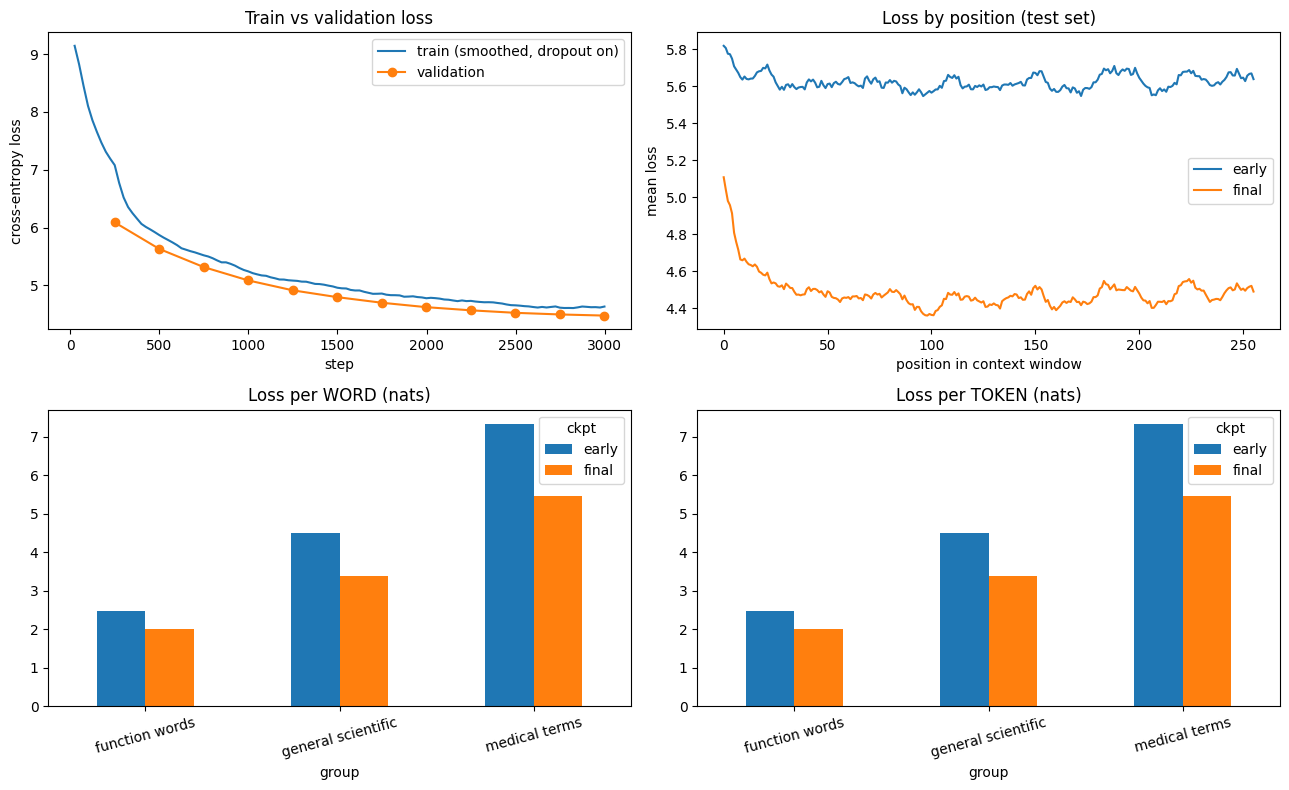

In [39]:
# ================= Task 8, Section A: how accurate is the model at next-token prediction? =================

from IPython.display import display

EVAL_BS, MAX_BATCHES = 16, None
best_model = MedGPTLightning.load_from_checkpoint("checkpoints/best/best.ckpt", map_location="cpu").model.to(device).eval()
split_at = max(50 * BATCH_SIZE, len(val_set) // 2)
val_part = PackedLMDataset(val_stream[: split_at * BLOCK_SIZE + 1], BLOCK_SIZE)

@torch.no_grad()
def evaluate(model, ds, max_batches=None, ks=(1, 5, 10)):
    model.eval()
    total, ntok, nseq, pos, hits = 0.0, 0, 0, torch.zeros(BLOCK_SIZE, device=device), dict.fromkeys(ks, 0)
    for b, batch in enumerate(DataLoader(ds, batch_size=EVAL_BS)):
        if max_batches and b >= max_batches:
            break
        x, y = batch["input_ids"].to(device), batch["labels"].to(device)
        logits = model(x).float()
        loss = F.cross_entropy(logits.reshape(-1, VOCAB), y.reshape(-1), reduction="none").view_as(y)
        total += loss.sum().item(); ntok += y.numel(); nseq += len(y); pos += loss.sum(0)
        match = logits.topk(max(ks), -1).indices == y.unsqueeze(-1)
        for k in ks:
            hits[k] += match[..., :k].any(-1).sum().item()
    mean = total / ntok
    return {"loss": mean, "perplexity": math.exp(mean), **{f"top-{k} acc": hits[k] / ntok for k in ks}, "pos": (pos / nseq).cpu().numpy()}

# ---- A1/A2: validation and test loss, perplexity, top-k accuracy (best checkpoint) ----
res = {name: evaluate(best_model, ds, MAX_BATCHES) for name, ds in [("validation", val_part), ("test", test_set)]}
display(pd.DataFrame({k: {m: v for m, v in r.items() if m != "pos"} for k, r in res.items()}).T.round(4))
print(f"Reference: a uniform guess gives loss {math.log(VOCAB):.2f} / perplexity {VOCAB}")

# ---- A3: loss curves (train vs validation) and per-position loss, early vs final checkpoint ----
log = pd.read_csv(Path(csv_logger.log_dir) / "metrics.csv")
tr, va = log[["step", "train_loss"]].dropna(), log[["step", "val_loss"]].dropna()
pos_loss = {name: evaluate(m, test_set, max_batches=60)["pos"] for name, m in models.items()}

fig, ax = plt.subplots(2, 2, figsize=(13, 8))
ax[0, 0].plot(tr.step, tr.train_loss.rolling(10, min_periods=1).mean(), label="train (smoothed, dropout on)")
ax[0, 0].plot(va.step, va.val_loss, "o-", label="validation")
ax[0, 0].set(xlabel="step", ylabel="cross-entropy loss", title="Train vs validation loss"); ax[0, 0].legend()
for name, v in pos_loss.items():
    ax[0, 1].plot(pd.Series(v).rolling(8, center=True, min_periods=1).mean(), label=name)
ax[0, 1].set(xlabel="position in context window", ylabel="mean loss", title="Loss by position (test set)"); ax[0, 1].legend()

# ---- A4: loss on medical terms vs common words (word level, since rare words span several tokens) ----
GROUPS = {
    "function words": "the of and in to was with for were is that by on as from are".split(),
    "general scientific": "patients study results treatment group effect increased significant cases clinical observed found cells disease data".split(),
    "medical terms": ("hypertension diabetes insulin carcinoma myocardial infarction thrombosis pneumonia leukemia lymphoma chemotherapy antibiotic "
                      "hepatitis cirrhosis arthritis epilepsy anemia ischemia hemorrhage glucose cholesterol creatinine hemoglobin penicillin aspirin "
                      "heparin tuberculosis schizophrenia bacteria tumor thyroid renal hepatic cardiac pulmonary antibodies syndrome prognosis sepsis asthma").split(),
}
lex = {}
for g, words in GROUPS.items():
    for w in words:
        lex.setdefault(tuple(tokenizer.encode(" " + w).ids), (g, w))
max_n, first = max(map(len, lex)), {k[0] for k in lex}
tok_text = [tokenizer.decode([i]) for i in range(VOCAB)]
is_cont = [bool(t) and not t[0].isspace() and any(c.isalnum() for c in t) for t in tok_text]

def find_words(yr, lr, min_pos=16):
    out = []
    for i in range(min_pos, BLOCK_SIZE - max_n):
        if yr[i] not in first:
            continue
        for n in range(1, max_n + 1):
            hit = lex.get(tuple(yr[i:i + n]))
            if hit and not is_cont[yr[i + n]]:
                out.append((hit[0], hit[1], sum(lr[i:i + n]), n)); break
    return out

@torch.no_grad()
def word_losses(model, label, max_batches=100):
    rows = []
    for b, batch in enumerate(DataLoader(test_set, batch_size=EVAL_BS)):
        if b >= max_batches:
            break
        x, y = batch["input_ids"].to(device), batch["labels"].to(device)
        loss = F.cross_entropy(model(x).float().reshape(-1, VOCAB), y.reshape(-1), reduction="none").view_as(y)
        for yr, lr in zip(y.tolist(), loss.tolist()):
            rows += [(label, *r) for r in find_words(yr, lr)]
    return pd.DataFrame(rows, columns=["ckpt", "group", "word", "loss", "ntok"])

occ = pd.concat([word_losses(m, name) for name, m in models.items()])
ws = occ.groupby(["ckpt", "group"]).agg(n=("loss", "size"), loss_per_word=("loss", "mean"), tokens_per_word=("ntok", "mean"),
                                        s=("loss", "sum"), t=("ntok", "sum"))
ws["loss_per_token"] = ws.s / ws.t
display(ws.drop(columns=["s", "t"]).round(3))
for a, col, title in [(ax[1, 0], "loss_per_word", "Loss per WORD (nats)"), (ax[1, 1], "loss_per_token", "Loss per TOKEN (nats)")]:
    ws.reset_index().pivot(index="group", columns="ckpt", values=col).reindex(list(GROUPS)).plot.bar(ax=a, rot=15, title=title)
plt.tight_layout(); plt.show()

In [40]:
# ================= Task 8, Section B: how useful is the model for a medical application? =================
import re, textwrap
from IPython.display import display

# ---- B1: review the Task 7 samples
NUM_CLAIM = re.compile(r"\d+(?:\.\d+)?\s?%|\d+(?:\.\d+)?\s?(?:mg|mcg|ug|µg|kg|g|ml|mmol|mmhg|iu)\b|\bp\s?[<=>]\s?0?\.\d+", re.I)
rev = samples_df[samples_df.checkpoint == "final"].copy()
rev["numeric_claim"] = rev.text.apply(lambda t: bool(NUM_CLAIM.search(t)))
rev["fluency_1to5"] = rev["plausibility_1to5"] = rev["correctness_1to5"] = ""
rev.to_csv(OUT_DIR / "manual_review_template.csv", index=False)
print("Final checkpoint, top-p samples to review (rubric saved to data/manual_review_template.csv):\n")
for _, r in rev[rev.strategy == "top-p=0.9"].iterrows():
    print(textwrap.fill("* " + r.text.replace("\n", " "), width=110, subsequent_indent="    "))
    print(f"    numeric claim: {r.numeric_claim}\n")

# ---- B2: probe domain knowledge: does the model rank the correct ending first? ----
FACTS = [
    ("Metformin is used in the treatment of",              " diabetes",    [" asthma", " epilepsy", " tuberculosis", " glaucoma"]),
    ("Insulin is used to treat patients with",             " diabetes",    [" asthma", " epilepsy", " pneumonia", " glaucoma"]),
    ("Penicillin is an antibiotic used to treat bacterial", " infections", [" fractures", " tumors", " cataracts", " migraines"]),
    ("Hypertension is defined as persistently elevated blood", " pressure", [" sugar", " calcium", " cholesterol", " iron"]),
    ("Diabetes mellitus is characterized by elevated blood", " glucose",   [" pressure", " calcium", " iron", " sodium"]),
    ("Statins are used to lower serum",                    " cholesterol", [" sodium", " creatinine", " potassium", " bilirubin"]),
    ("Pneumonia is an infection of the",                   " lungs",       [" kidneys", " liver", " skin", " brain"]),
    ("Cirrhosis is a chronic disease of the",              " liver",       [" lungs", " kidneys", " heart", " skin"]),
    ("Glaucoma is a disease of the",                       " eye",         [" liver", " kidney", " lung", " skin"]),
    ("Epilepsy is a neurological disorder characterized by recurrent", " seizures", [" fractures", " infections", " tumors", " fevers"]),
    ("Chemotherapy is commonly used in the treatment of",  " cancer",      [" fractures", " asthma", " cataracts", " hernias"]),
    ("Jaundice is caused by elevated",                     " bilirubin",   [" glucose", " sodium", " calcium", " cholesterol"]),
]

@torch.no_grad()
def ending_logprob(model, prefix, ending):
    p_ids, f_ids = tokenizer.encode(prefix).ids, tokenizer.encode(prefix + ending).ids
    k = 0
    while k < min(len(p_ids), len(f_ids)) and p_ids[k] == f_ids[k]:
        k += 1
    logp = F.log_softmax(model(torch.tensor([f_ids[:-1]], device=device))[0].float(), dim=-1)
    lp = logp.gather(1, torch.tensor(f_ids[1:], device=device)[:, None])[:, 0][max(k, 1) - 1:]
    return lp.sum().item(), lp.mean().item()

def rank_of_correct(model):
    rows = []
    for prefix, correct, wrong in FACTS:
        cands = [correct] + wrong
        sc = np.array([ending_logprob(model, prefix, c) for c in cands])
        rows.append({"prefix": prefix, "correct": correct.strip(),
                     "rank": int((sc[:, 0] > sc[0, 0]).sum()) + 1,
                     "rank_norm": int((sc[:, 1] > sc[0, 1]).sum()) + 1,
                     "model picks": cands[sc[:, 0].argmax()].strip()})
    return pd.DataFrame(rows)

probe = {name: rank_of_correct(m) for name, m in models.items()}
display(pd.DataFrame({name: {"top-1 acc": (d["rank"] == 1).mean(), "top-1 acc (length-norm.)": (d.rank_norm == 1).mean(),
                             "MRR": (1 / d["rank"]).mean()} for name, d in probe.items()}).T.round(3))
print(f"Chance: top-1 = {1/5:.2f}, MRR = {np.mean([1/r for r in range(1, 6)]):.2f}  ({len(FACTS)} items, 5 candidates each; small sample, so treat as a probe)\n")
display(probe["final"].assign(rank_early=probe["early"]["rank"].values).rename(columns={"rank": "rank_final"}))

# ---- B3: other benchmarks worth exploring ----
print("""Other medical benchmarks to explore (a 7M-parameter model will be near chance on most of them):
  BioLAMA     cloze-style factual probing of biomedical LMs   -> closest to B2; scale it up from UMLS/MeSH/DrugBank relations
  PubMedQA    yes/no/maybe questions answered from abstracts   -> same domain as our data; needs fine-tuning
  MedMCQA, MedQA (USMLE), MMLU medical subsets                 -> multiple-choice exam questions; far beyond this model
  BLURB, BioASQ                                                -> biomedical NLP suite / QA challenge; need fine-tuning or retrieval
  HealthBench                                                  -> physician-rubric scoring of free-text health answers
Better fits at this scale: perplexity by year/section, larger KB-built fact probes, memorisation and number-hallucination audits,
calibration, comparison with GPT-2 small and an n-gram LM on the same test text, and clinician review of a fixed sample.""")

Final checkpoint, top-p samples to review (rubric saved to data/manual_review_template.csv):

* The patient presented with malignant malignancy. Following removal of the tumor were done with carcinoma
    (N+BB), three times of late tumors, and iatta caseiophagen) carcinoma was applied to a multicip gland of
    pre-light tumor of intrajeffingomas-we. Other lesions were localized in the vertebral ducts of the pelvis.
    These cases contained the glomerular metastasis in the trunk (N).
    numeric claim: False

* Treatment of type 2 diabetes includes a simple excretion of vitamin A by dergide like D (N+ -B), p-cystorial
    obstruction. Dieling caseiitis, associated with any symptoms or a multicip gland are preprolactinosis of
    immune origin. This case appears to be a precise advantage if either the method of choice is not sole
    factors and to lead to the primary exacerbation of bile duct with
    numeric claim: False

* The most common side effects of chemotherapy are discussed 

,top-1 acc,top-1 acc (length-norm.),MRR
early,0.417,0.417,0.617
final,0.333,0.333,0.596


Chance: top-1 = 0.20, MRR = 0.46  (12 items, 5 candidates each; small sample, so treat as a probe)



,prefix,correct,rank_final,rank_norm,model picks,rank_early
0,Metformin is used in the treatment of,diabetes,2,2,asthma,1
1,Insulin is used to treat patients with,diabetes,2,2,asthma,1
2,Penicillin is an antibiotic used to treat bacterial,infections,1,1,infections,2
3,Hypertension is defined as persistently elevated blood,pressure,1,1,pressure,1
4,Diabetes mellitus is characterized by elevated blood,glucose,2,2,pressure,2
5,Statins are used to lower serum,cholesterol,1,1,cholesterol,1
6,Pneumonia is an infection of the,lungs,4,4,liver,5
7,Cirrhosis is a chronic disease of the,liver,1,1,liver,2
8,Glaucoma is a disease of the,eye,5,5,liver,4
9,Epilepsy is a neurological disorder characterized by recurrent,seizures,2,2,infections,4


Other medical benchmarks to explore (a 7M-parameter model will be near chance on most of them):
  BioLAMA     cloze-style factual probing of biomedical LMs   -> closest to B2; scale it up from UMLS/MeSH/DrugBank relations
  PubMedQA    yes/no/maybe questions answered from abstracts   -> same domain as our data; needs fine-tuning
  MedMCQA, MedQA (USMLE), MMLU medical subsets                 -> multiple-choice exam questions; far beyond this model
  BLURB, BioASQ                                                -> biomedical NLP suite / QA challenge; need fine-tuning or retrieval
  HealthBench                                                  -> physician-rubric scoring of free-text health answers
Better fits at this scale: perplexity by year/section, larger KB-built fact probes, memorisation and number-hallucination audits,
calibration, comparison with GPT-2 small and an n-gram LM on the same test text, and clinician review of a fixed sample.
